CD- 1 | Final MSE: 0.1270 | Time: 0.64s
CD- 5 | Final MSE: 0.1267 | Time: 1.65s
CD-10 | Final MSE: 0.1266 | Time: 2.52s


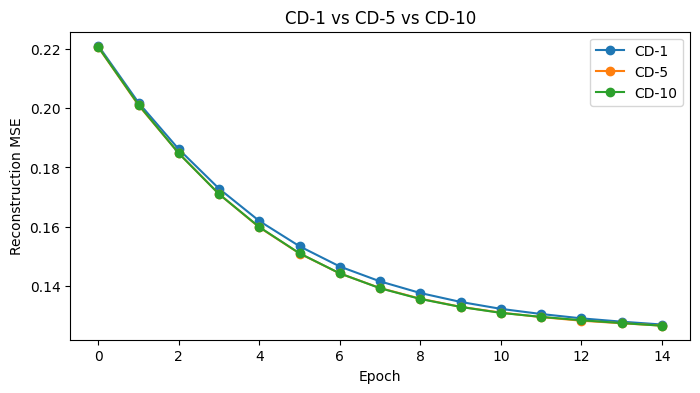

In [23]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

X = (load_digits().data[:300] > 8).astype(np.float32)
n_vis, n_hid = 64, 32
sig = lambda x: 1.0 / (1.0 + np.exp(-np.clip(x, -20, 20)))

def train_cd(k_steps, epochs=15):
    rng = np.random.default_rng(42)
    W = rng.normal(0, 0.1, (n_vis, n_hid))
    a, b = np.zeros(n_vis), np.zeros(n_hid)
    t0 = time.time()
    curve = []
    for _ in range(epochs):
        for v0 in X:
            ph0 = sig(v0 @ W + b)
            h = (rng.random(n_hid) < ph0).astype(float)
            for _ in range(k_steps):
                pv = sig(h @ W.T + a)
                v = (rng.random(n_vis) < pv).astype(float)
                ph = sig(v @ W + b)
                h = (rng.random(n_hid) < ph).astype(float)
            W += 0.05 * (np.outer(v0, ph0) - np.outer(v, ph)) / len(X)
            a += 0.05 * (v0 - v) / len(X)
            b += 0.05 * (ph0 - ph) / len(X)
        rec = sig(sig(X @ W + b) @ W.T + a)
        curve.append(np.mean((X - rec) ** 2))
    return curve, time.time() - t0

plt.figure(figsize=(8, 4))
for k in [1, 5, 10]:
    c, dt = train_cd(k)
    print(f"CD-{k:2d} | Final MSE: {c[-1]:.4f} | Time: {dt:.2f}s")
    plt.plot(c, marker="o", label=f"CD-{k}")
plt.xlabel("Epoch"); plt.ylabel("Reconstruction MSE"); plt.title("CD-1 vs CD-5 vs CD-10"); plt.legend(); plt.show()